In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import kagglehub
from datasets import load_dataset
from sklearn.preprocessing import LabelEncoder
from tensorflow import keras
import tensorflow as tf
import tensorflow_addons as tfa
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Dropout, Input, Concatenate
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import classification_report, f1_score
import re
import unicodedata
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from imblearn.over_sampling import RandomOverSampler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

c:\Users\Barsam\miniconda3\envs\Y2bA\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


c:\Users\Barsam\miniconda3\envs\Y2bA\lib\site-packages\tensorflow_addons\utils\tfa_eol_msg.py:23: UserWarning: 

TensorFlow Addons (TFA) has ended development and introduction of new features.
TFA has entered a minimal maintenance and release mode until a planned end of life in May 2024.
Please modify downstream libraries to take dependencies from other repositories in our TensorFlow community (e.g. Keras, Keras-CV, and Keras-NLP). 

For more information see: https://github.com/tensorflow/addons/issues/2807 

  warnings.warn(
c:\Users\Barsam\miniconda3\envs\Y2bA\lib\site-packages\tensorflow_addons\utils\ensure_tf_install.py:53: UserWarning: Tensorflow Addons supports using Python ops for all Tensorflow versions above or equal to 2.12.0 and strictly below 2.15.0 (nightly versions are not supported). 
 The versions of TensorFlow you are currently using is 2.15.0 and is not supported. 
Some things might work, some things might not.
If you were to encounter a bug, do not file an issue.
If 

In [2]:
df = pd.read_excel("nnnhis_year_and_last_year_cleanedmix_shuffled1.xlsx")
df = df.rename(columns={"emotion_core":"emotion"})
df = df[["sentence", "emotion"]]
df["sentence"] = df["sentence"].astype(str)
df.head()

,sentence,emotion
0,I feel horrible.,sadness
1,He wants to couple with her.,happiness
2,"basketball, his life revolved around their liv...",happiness
3,I've made a decision to strengthen the team.,neutral
4,My throat’s dry.,fear


# Iteration 1: Baseline RNN

In [3]:
# Encode emotions
label_encoder = LabelEncoder()
df["label"] = label_encoder.fit_transform(df["emotion"])

X = df["sentence"].values
y = df["label"].values

# split into train validation split
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size = 0.1, random_state=42, stratify=y
)

In [4]:
max_words = 20000 # keep the 20000 most common words in the corpus so the model doesnt waste time training sentences that only happen onces
max_len = 100 # Fix input length for padding the vectors

# Build vocabulary from trainig data
tokenzier = Tokenizer(num_words=max_words, oov_token="<OOV>") # replace words out of the corpus with OOV
tokenzier.fit_on_texts(X_train)

# Convert sentences into integer sequences 
X_train_seq = tokenzier.texts_to_sequences(X_train)
X_val_seq = tokenzier.texts_to_sequences(X_val)

# pad to fix length issues
X_train_pad = pad_sequences(X_train_seq, maxlen=max_len, padding="post", truncating="post")
X_val_pad = pad_sequences(X_val_seq, maxlen=max_len, padding="post", truncating="post")

In [5]:
embedding_dim = 128

model_1 = Sequential([
    Embedding(input_dim = max_words, output_dim = embedding_dim, input_length = max_len),
    SimpleRNN(128, return_sequences=False),
    Dropout(0.5),
    Dense(64, activation = "relu"),
    Dropout(0.3),
    Dense(len(label_encoder.classes_), activation = "softmax")
])

model_1.compile(
    loss = "sparse_categorical_crossentropy",
    optimizer = "adam",
    metrics = ["accuracy"]
)

model_1.summary()



Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding (Embedding)       (None, 100, 128)          2560000   
                                                                 
 simple_rnn (SimpleRNN)      (None, 128)               32896     
                                                                 
 dropout (Dropout)           (None, 128)               0         
                                                                 
 dense (Dense)               (None, 64)                8256      
                                                                 
 dropout_1 (Dropout)         (None, 64)                0         
                                                                 
 dense_1 (Dense)             (None, 7)                 455       
                                                                 
Total params: 2601607 (9.92 MB)
Trainable params: 2601

In [6]:
h1 = model_1.fit(
    X_train_pad, y_train,
    validation_data = (X_val_pad, y_val),
    epochs = 5,
    batch_size = 32,
    verbose = 1
)

Epoch 1/5


826/826 [==============================] - 15s 17ms/step - loss: 1.7846 - accuracy: 0.3322 - val_loss: 1.7474 - val_accuracy: 0.3484
Epoch 2/5
826/826 [==============================] - 14s 17ms/step - loss: 1.7526 - accuracy: 0.3484 - val_loss: 1.7561 - val_accuracy: 0.3484
Epoch 3/5
826/826 [==============================] - 14s 17ms/step - loss: 1.7543 - accuracy: 0.3465 - val_loss: 1.7427 - val_accuracy: 0.3484
Epoch 4/5
826/826 [==============================] - 14s 17ms/step - loss: 1.7458 - accuracy: 0.3483 - val_loss: 1.7389 - val_accuracy: 0.3484
Epoch 5/5
826/826 [==============================] - 14s 17ms/step - loss: 1.7444 - accuracy: 0.3480 - val_loss: 1.7374 - val_accuracy: 0.3484


In [7]:
# Loading and pre process test dataset
df_test = pd.read_csv("group_23_url_1_transcript.csv")
# Keep only the necessary columns
df_test = df_test[["Sentence", "Emotion_core"]]
df_test.head()

,Sentence,Emotion_core
0,"Previously on Australian Survivor, Tara and Lo...",happiness
1,I'm trusting you with this because I'm sitting...,fear
2,But Tara decided it was time for a breakup.,sadness
3,"It breaks my heart, but he's got to go.",sadness
4,It wasn't the only moral dilemma Tara faced.,neutral


In [8]:
# Encode labels with the same encoder used in training
df_test["label"] = label_encoder.transform(df_test["Emotion_core"])

X_test = df_test["Sentence"].values
y_test = df_test["label"].values

# Tokenize and pad with the same tokenizer
X_test_seq = tokenzier.texts_to_sequences(X_test)
X_test_pad = pad_sequences(X_test_seq, maxlen=max_len, padding="post", truncating="post")

# Get predictions
y_test_pred = model_1.predict(X_test_pad)
y_test_pred_classes = y_test_pred.argmax(axis = 1)

# Compute macro F1 
macro_f1 = f1_score(y_test, y_test_pred_classes, average="macro")
print("Macro F1 score on Test Data:", macro_f1)

# Detailed per class evaluation report
print(classification_report(y_test, y_test_pred_classes, target_names=label_encoder.classes_))

21/21 [==============================] - 0s 4ms/step
Macro F1 score on Test Data: 0.06832298136645963
              precision    recall  f1-score   support

       anger       0.00      0.00      0.00        54
     disgust       0.00      0.00      0.00         6
        fear       0.00      0.00      0.00       101
   happiness       0.00      0.00      0.00       156
     neutral       0.31      1.00      0.48       209
     sadness       0.00      0.00      0.00        88
    surprise       0.00      0.00      0.00        51

    accuracy                           0.31       665
   macro avg       0.04      0.14      0.07       665
weighted avg       0.10      0.31      0.15       665



c:\Users\Barsam\miniconda3\envs\Y2bA\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Barsam\miniconda3\envs\Y2bA\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Barsam\miniconda3\envs\Y2bA\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


21/21 [==============================] - 0s 3ms/step


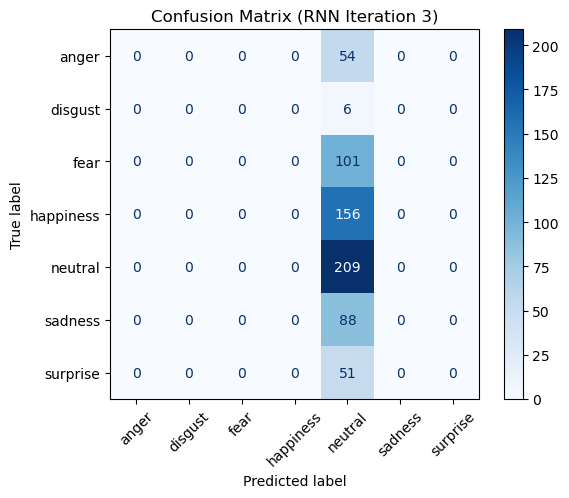

In [9]:
# Get predictions (example for iteration 3 model)
y_test_pred = model_1.predict(X_test_pad).argmax(axis=1)

# Compute confusion matrix
cm = confusion_matrix(y_test, y_test_pred)

# Plot confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_encoder.classes_)
disp.plot(cmap=plt.cm.Blues, xticks_rotation=45)
plt.title("Confusion Matrix (RNN Iteration 3)")
plt.show()

In [10]:
# Predict on validation set
y_val_pred = model_1.predict(X_val_pad)
y_val_pred_classes = y_val_pred.argmax(axis=1)

# Compute Macro F1
macro_f1_val = f1_score(y_val, y_val_pred_classes, average="macro")
print("Macro F1 Score on Validation Data:", macro_f1_val)

# Full classification report
print(classification_report(y_val, y_val_pred_classes, target_names=label_encoder.classes_))

92/92 [==============================] - 0s 4ms/step
Macro F1 Score on Validation Data: 0.0738281672861112
              precision    recall  f1-score   support

       anger       0.00      0.00      0.00       279
     disgust       0.00      0.00      0.00       226
        fear       0.00      0.00      0.00       272
   happiness       0.00      0.00      0.00       698
     neutral       0.35      1.00      0.52      1023
     sadness       0.00      0.00      0.00       240
    surprise       0.00      0.00      0.00       198

    accuracy                           0.35      2936
   macro avg       0.05      0.14      0.07      2936
weighted avg       0.12      0.35      0.18      2936



c:\Users\Barsam\miniconda3\envs\Y2bA\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Barsam\miniconda3\envs\Y2bA\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Barsam\miniconda3\envs\Y2bA\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


# Iteration 2: Pre processing + POS tagging

In [11]:
# Pre-processing texts

def preprocess_text(text):
    # handling missing values
    if pd.isna(text):
        return ""
    text = str(text)
    text = text.lower()

    #Normalize weird unicode (removing things like Ä, non-breaking spaces)
    text = unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode("utf-8", "ignore")

    # Keep letters and punctuation (! ? . , …) but drop numbers/symbols
    text = re.sub(r"[^a-zA-Z!?.,'\s]", " ", text)

    # Removing usernames / mentions
    text = re.sub(r"@\w", " ", text)

    # Removing things like [NAME] or [something]
    text = re.sub(r"\[.*?\]", " ", text)

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


In [12]:
df = df.dropna(subset=["sentence"])
df = df.drop_duplicates(subset=["sentence"])
df["clean_sentence"] = df["sentence"].apply(preprocess_text)

In [13]:
import spacy

# Load SpaCy model
nlp = spacy.load("en_core_web_sm")

def get_pos_features(text):
    doc = nlp(text)
    counts = {"ADJ":0, "ADV":0, "NOUN":0, "VERB":0}
    for token in doc:
        if token.pos_ == "ADJ":
            counts["ADJ"] += 1
        elif token.pos_ == "ADV":
            counts["ADV"] += 1
        elif token.pos_ == "NOUN":
            counts["NOUN"] += 1
        elif token.pos_ == "VERB":
            counts["VERB"] += 1
    return list(counts.values())

# Apply to dataset
pos_features = df["clean_sentence"].apply(get_pos_features)
pos_features = np.array(pos_features.tolist())
print(pos_features.shape, pos_features[:5], pos_features.dtype)

c:\Users\Barsam\miniconda3\envs\Y2bA\lib\site-packages\jsonschema\__init__.py:32: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution


(25905, 4) [[1 0 0 1]
 [0 0 0 2]
 [1 1 3 1]
 [0 0 2 2]
 [0 0 1 1]] int32


In [14]:
# Tokenize and pad the input

X_seq = tokenzier.texts_to_sequences(df["sentence"].values)
X_pad = pad_sequences(X_seq, maxlen=max_len, padding = "post", truncating="post")

# Split into training and validation sets for both the input and the sentiment scores 
X_train_pad, X_val_pad, pos_train, pos_val, y_train, y_val = train_test_split(
    X_pad, pos_features, df["label"].values, test_size = 0.1,
    random_state=42, stratify=df["label"].values
)

In [15]:
## Building model

# Text branch
text_in = Input(shape=(max_len), name = "text_input")
x = Embedding(input_dim = max_words, output_dim = embedding_dim, input_length = max_len)(text_in)
x = SimpleRNN(128, return_sequences=False)(x)
x = Dropout(0.5)(x)

# POS branch
pos_in = Input(shape=(pos_train.shape[1],), name="pos_input")
p = Dense(16, activation="relu")(pos_in)

# Combine branches
combined = Concatenate()([x, p])
out = Dense(len(label_encoder.classes_), activation = "softmax")(combined)

# Build model
model_2 = Model(inputs = [text_in, pos_in], outputs = out)

model_2.compile(
    loss = "sparse_categorical_crossentropy",
    optimizer = "adam",
    metrics =["accuracy"]
)

model_2.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 text_input (InputLayer)     [(None, 100)]                0         []                            
                                                                                                  
 embedding_1 (Embedding)     (None, 100, 128)             2560000   ['text_input[0][0]']          
                                                                                                  
 simple_rnn_1 (SimpleRNN)    (None, 128)                  32896     ['embedding_1[0][0]']         
                                                                                                  
 pos_input (InputLayer)      [(None, 4)]                  0         []                            
                                                                                              

In [16]:
# Flatten out sequence and sentiment features into one array for oversampling
X_train_combined = np.hstack([X_train_pad, pos_train])

ros = RandomOverSampler(random_state=42)
X_resampled, y_resampled = ros.fit_resample(X_train_combined, y_train)

X_train_pad_resampled = X_resampled[:, :X_train_pad.shape[1]]
pos_train_resampled = X_resampled[:, X_train_pad.shape[1]:]

print("Before:", np.bincount(y_train))
print("After:", np.bincount(y_resampled))

Before: [2303 1854 2204 5713 7819 2033 1388]
After: [7819 7819 7819 7819 7819 7819 7819]


c:\Users\Barsam\miniconda3\envs\Y2bA\lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\Users\Barsam\miniconda3\envs\Y2bA\lib\site-packages\sklearn\base.py:484: FutureWarning: `BaseEstimator._check_n_features` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_n_features` instead.
  warnings.warn(
c:\Users\Barsam\miniconda3\envs\Y2bA\lib\site-packages\sklearn\base.py:493: FutureWarning: `BaseEstimator._check_feature_names` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_feature_names` instead.
  warnings.warn(


In [17]:
early_stop = EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)

h2 = model_2.fit(
    [X_train_pad_resampled, pos_train_resampled], y_resampled,
    validation_data = ([X_val_pad, pos_val], y_val),
    epochs = 50,
    batch_size = 32,
    callbacks = [early_stop],
    verbose = 1
)

Epoch 1/50
1711/1711 [==============================] - 29s 17ms/step - loss: 1.9823 - accuracy: 0.1819 - val_loss: 1.8968 - val_accuracy: 0.2269
Epoch 2/50
1711/1711 [==============================] - 27s 16ms/step - loss: 1.9044 - accuracy: 0.2156 - val_loss: 1.8606 - val_accuracy: 0.2416
Epoch 3/50
1711/1711 [==============================] - 28s 16ms/step - loss: 1.8730 - accuracy: 0.2351 - val_loss: 1.8316 - val_accuracy: 0.2713
Epoch 4/50
1711/1711 [==============================] - 29s 17ms/step - loss: 1.8818 - accuracy: 0.2278 - val_loss: 1.8545 - val_accuracy: 0.2431
Epoch 5/50
1711/1711 [==============================] - 29s 17ms/step - loss: 1.8831 - accuracy: 0.2279 - val_loss: 1.8791 - val_accuracy: 0.2080


In [18]:
pos_test= df_test["Sentence"].apply(get_pos_features)
pos_test = np.array(pos_test.tolist())

print(pos_test.shape)
print(pos_test[:5])

(665, 4)
[[1 1 2 0]
 [0 0 2 2]
 [0 0 2 1]
 [0 0 1 3]
 [2 0 1 1]]


In [19]:
# Get predictions
y_test_pred = model_2.predict([X_test_pad, pos_test])
y_test_pred_classes = y_test_pred.argmax(axis = 1)

# Compute macro F1 
macro_f1 = f1_score(y_test, y_test_pred_classes, average="macro")
print("Macro F1 score on Test Data:", macro_f1)

# Detailed per class evaluation report
print(classification_report(y_test, y_test_pred_classes, target_names=label_encoder.classes_))

21/21 [==============================] - 0s 4ms/step
Macro F1 score on Test Data: 0.20785711385664343
              precision    recall  f1-score   support

       anger       0.18      0.24      0.21        54
     disgust       0.03      0.33      0.05         6
        fear       0.23      0.20      0.21       101
   happiness       0.34      0.35      0.34       156
     neutral       0.45      0.34      0.39       209
     sadness       0.24      0.11      0.16        88
    surprise       0.09      0.12      0.10        51

    accuracy                           0.27       665
   macro avg       0.22      0.24      0.21       665
weighted avg       0.31      0.27      0.28       665



21/21 [==============================] - 0s 3ms/step


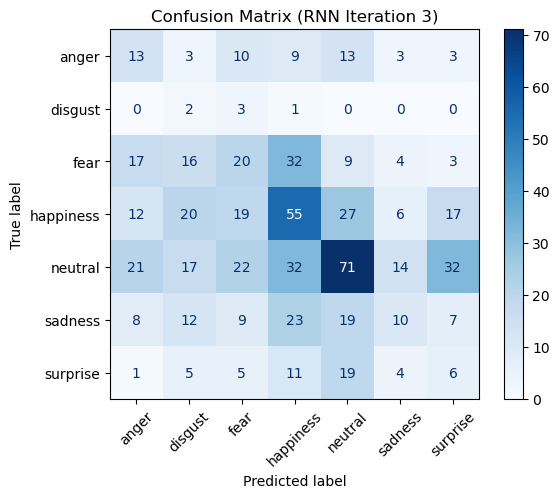

In [20]:
# Get predictions (example for iteration 3 model)
y_test_pred = model_2.predict([X_test_pad, pos_test]).argmax(axis=1)

# Compute confusion matrix
cm = confusion_matrix(y_test, y_test_pred)

# Plot confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_encoder.classes_)
disp.plot(cmap=plt.cm.Blues, xticks_rotation=45)
plt.title("Confusion Matrix (RNN Iteration 3)")
plt.show()

In [21]:
# Predict on validation set
y_val_pred = model_2.predict([X_val_pad, pos_val])
y_val_pred_classes = y_val_pred.argmax(axis=1)

# Compute Macro F1
macro_f1_val = f1_score(y_val, y_val_pred_classes, average="macro")
print("Macro F1 Score on Validation Data:", macro_f1_val)

# Full classification report
print(classification_report(y_val, y_val_pred_classes, target_names=label_encoder.classes_))

81/81 [==============================] - 0s 4ms/step
Macro F1 Score on Validation Data: 0.2211981441201643
              precision    recall  f1-score   support

       anger       0.16      0.16      0.16       256
     disgust       0.17      0.45      0.25       206
        fear       0.19      0.16      0.17       245
   happiness       0.35      0.30      0.32       635
     neutral       0.45      0.33      0.38       869
     sadness       0.15      0.13      0.14       226
    surprise       0.10      0.15      0.12       154

    accuracy                           0.27      2591
   macro avg       0.23      0.24      0.22      2591
weighted avg       0.31      0.27      0.28      2591



# Iteration 3: POS tagging + sentiment analysis + TF_IDF

In [22]:
# Sentiment Analysis
nltk.download("vader_lexicon")
sid = SentimentIntensityAnalyzer()

def get_sentiment_scores(text):
    scores = sid.polarity_scores(str(text))
    return [scores["neg"], scores["neu"], scores["pos"], scores["compound"]] # The different scores we want to get

sentiment_features = df["sentence"].apply(get_sentiment_scores)
sentiment_features = np.array(sentiment_features.tolist())

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\Barsam/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


In [23]:
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1,2))

X_tfidf = tfidf.fit_transform(df["clean_sentence"]).toarray()
print("TF-IDF shape:", X_tfidf.shape)

TF-IDF shape: (25905, 5000)


In [24]:
# Load SpaCy model
nlp = spacy.load("en_core_web_sm")

def get_pos_features(text):
    doc = nlp(text)
    counts = {"ADJ":0, "ADV":0, "NOUN":0, "VERB":0}
    for token in doc:
        if token.pos_ == "ADJ":
            counts["ADJ"] += 1
        elif token.pos_ == "ADV":
            counts["ADV"] += 1
        elif token.pos_ == "NOUN":
            counts["NOUN"] += 1
        elif token.pos_ == "VERB":
            counts["VERB"] += 1
    return list(counts.values())

# Apply to dataset
pos_features = df["clean_sentence"].apply(get_pos_features)
pos_features = np.array(pos_features.tolist())
print(pos_features.shape, pos_features[:5], pos_features.dtype)

(25905, 4) [[1 0 0 1]
 [0 0 0 2]
 [1 1 3 1]
 [0 0 2 2]
 [0 0 1 1]] int32


In [25]:
# Tokenize and pad the input

X_seq = tokenzier.texts_to_sequences(df["sentence"].values)
X_pad = pad_sequences(X_seq, maxlen=max_len, padding = "post", truncating="post")

# Split into training and validation sets for the input, sentiment scores, and the POS tags
X_train_pad, X_val_pad, sent_train, sent_val, pos_train, pos_val, tfidf_train, tfidf_val, y_train, y_val = train_test_split(
    X_pad, sentiment_features,pos_features, X_tfidf, df["label"].values, test_size = 0.1,
    random_state=42, stratify=df["label"].values
)


In [26]:
## Building the model

seq_input = Input(shape=(max_len,))
embedding_layer = Embedding(
    input_dim = max_words,
    output_dim = 128,
    input_length = max_len,
    trainable = True
)(seq_input)

# Stacked LSTM layers
x = SimpleRNN(128, return_sequences=True)(embedding_layer)
x = Dropout(0.5)(x)
x = SimpleRNN(64)(x)
x = Dropout(0.3)(x)

# Sentiment input
sent_input = Input(shape=(4,))
dense_sent = Dense(16, activation = "relu")(sent_input)

# POS input
pos_input = Input(shape=(4,))
dense_pos = Dense(16, activation = "relu")(pos_input)


# TF-IDF branch
tfidf_input = Input(shape=(X_tfidf.shape[1],))
dense_tfidf = Dense(128, activation = "relu")(tfidf_input)
dense_tfidf = Dropout(0.3)(dense_tfidf)

# Merge
merged = Concatenate()([x, dense_sent, dense_pos, dense_tfidf])
dense_out = Dense(64, activation = "relu")(merged)
dropout = Dropout(0.3)(dense_out)
final_out = Dense(len(label_encoder.classes_), activation = "softmax")(dropout)

#Build model
model_3 = Model(inputs=[seq_input, pos_input, sent_input, tfidf_input], outputs = final_out)
model_3.compile(loss = "sparse_categorical_crossentropy",
                optimizer = "adam", 
                metrics = ["accuracy"])

model_3.summary()

Model: "model_1"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 100)]                0         []                            
                                                                                                  
 embedding_2 (Embedding)     (None, 100, 128)             2560000   ['input_1[0][0]']             
                                                                                                  
 simple_rnn_2 (SimpleRNN)    (None, 100, 128)             32896     ['embedding_2[0][0]']         
                                                                                                  
 dropout_3 (Dropout)         (None, 100, 128)             0         ['simple_rnn_2[0][0]']        
                                                                                            

In [27]:
# Stack sentiment, POS, TF-IDF for resampling together
extra_train = np.hstack([sent_train, pos_train, tfidf_train])

# Oversample
ros = RandomOverSampler(random_state=42)
extra_resampled, y_train_resampled = ros.fit_resample(extra_train, y_train)

# Get indices of rows that were resampled
indices = ros.sample_indices_

# Apply same resampling to padded sequences
X_train_pad_resampled = X_train_pad[indices]

# Now split extra_resampled back into features
sent_train_resampled = extra_resampled[:, :sent_train.shape[1]]
pos_train_resampled  = extra_resampled[:, sent_train.shape[1]:sent_train.shape[1]+pos_train.shape[1]]
tfidf_train_resampled = extra_resampled[:, sent_train.shape[1]+pos_train.shape[1]:]

c:\Users\Barsam\miniconda3\envs\Y2bA\lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\Users\Barsam\miniconda3\envs\Y2bA\lib\site-packages\sklearn\base.py:484: FutureWarning: `BaseEstimator._check_n_features` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_n_features` instead.
  warnings.warn(
c:\Users\Barsam\miniconda3\envs\Y2bA\lib\site-packages\sklearn\base.py:493: FutureWarning: `BaseEstimator._check_feature_names` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_feature_names` instead.
  warnings.warn(


In [28]:
h3 = model_3.fit(
    [X_train_pad_resampled, sent_train_resampled, pos_train_resampled, tfidf_train_resampled], y_resampled,
    validation_data=([X_val_pad, sent_val, pos_val, tfidf_val], y_val),
    epochs=10,        
    batch_size=32,
    callbacks = [early_stop],
    verbose=1
)

Epoch 1/10
1711/1711 [==============================] - 43s 24ms/step - loss: 1.3432 - accuracy: 0.4824 - val_loss: 1.2957 - val_accuracy: 0.5071
Epoch 2/10
1711/1711 [==============================] - 41s 24ms/step - loss: 0.7827 - accuracy: 0.7197 - val_loss: 1.4069 - val_accuracy: 0.5145
Epoch 3/10
1711/1711 [==============================] - 41s 24ms/step - loss: 0.5717 - accuracy: 0.7952 - val_loss: 1.5132 - val_accuracy: 0.5384


In [29]:
pos_test= df_test["Sentence"].apply(get_pos_features)
pos_test = np.array(pos_test.tolist())

print(pos_test.shape)
print(pos_test[:5])

(665, 4)
[[1 1 2 0]
 [0 0 2 2]
 [0 0 2 1]
 [0 0 1 3]
 [2 0 1 1]]


In [30]:
tfidf_test  = tfidf.transform(X_test).toarray()
print("TF-IDF shape:", tfidf_test.shape)

TF-IDF shape: (665, 5000)


In [31]:
# Generate sentiment features for test sentences
sent_test = df_test["Sentence"].apply(get_sentiment_scores)
sent_test = np.array(sent_test.tolist())

print(sent_test.shape)
print(sent_test[:5])

(665, 4)
[[ 0.      0.839   0.161   0.3612]
 [ 0.      0.828   0.172   0.4019]
 [ 0.      1.      0.      0.    ]
 [ 0.      1.      0.      0.    ]
 [ 0.195   0.805   0.     -0.1779]]


In [32]:
# Get predictions
y_test_pred = model_3.predict([X_test_pad, sent_test, pos_test, tfidf_test])
y_test_pred_classes = y_test_pred.argmax(axis = 1)

# Compute macro F1 
macro_f1 = f1_score(y_test, y_test_pred_classes, average="macro")
print("Macro F1 score on Test Data:", macro_f1)

# Detailed per class evaluation report
print(classification_report(y_test, y_test_pred_classes, target_names=label_encoder.classes_))

21/21 [==============================] - 0s 6ms/step
Macro F1 score on Test Data: 0.39183331428495827
              precision    recall  f1-score   support

       anger       0.28      0.39      0.32        54
     disgust       0.12      0.17      0.14         6
        fear       0.48      0.35      0.40       101
   happiness       0.50      0.69      0.58       156
     neutral       0.57      0.39      0.46       209
     sadness       0.31      0.33      0.32        88
    surprise       0.47      0.55      0.51        51

    accuracy                           0.46       665
   macro avg       0.39      0.41      0.39       665
weighted avg       0.47      0.46      0.45       665



21/21 [==============================] - 0s 6ms/step


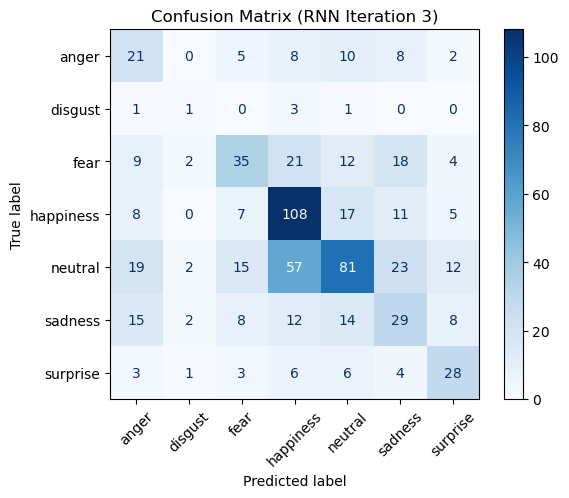

In [33]:

# Get predictions (example for iteration 3 model)
y_test_pred = model_3.predict([X_test_pad, sent_test, pos_test, tfidf_test]).argmax(axis=1)

# Compute confusion matrix
cm = confusion_matrix(y_test, y_test_pred)

# Plot confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_encoder.classes_)
disp.plot(cmap=plt.cm.Blues, xticks_rotation=45)
plt.title("Confusion Matrix (RNN Iteration 3)")
plt.show()

In [34]:
# Predict on validation set
y_val_pred = model_3.predict([X_val_pad, sent_val, pos_val, tfidf_val])
y_val_pred_classes = y_val_pred.argmax(axis=1)

# Compute Macro F1
macro_f1_val = f1_score(y_val, y_val_pred_classes, average="macro")
print("Macro F1 Score on Validation Data:", macro_f1_val)

# Full classification report
print(classification_report(y_val, y_val_pred_classes, target_names=label_encoder.classes_))

81/81 [==============================] - 0s 6ms/step
Macro F1 Score on Validation Data: 0.5023055247669681
              precision    recall  f1-score   support

       anger       0.38      0.54      0.44       256
     disgust       0.55      0.61      0.58       206
        fear       0.64      0.57      0.60       245
   happiness       0.55      0.53      0.54       635
     neutral       0.60      0.44      0.51       869
     sadness       0.37      0.53      0.43       226
    surprise       0.36      0.48      0.41       154

    accuracy                           0.51      2591
   macro avg       0.49      0.53      0.50      2591
weighted avg       0.53      0.51      0.51      2591

